<a href="https://colab.research.google.com/github/Zafeerxyz/Machine-Learning-algorithms/blob/main/Auto_encoder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install tensorflow scikit-learn pandas matplotlib

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

In [ ]:
wine = load_wine()

X = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test = train_test_split(
    X_scaled,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(142, 13)
(36, 13)


In [ ]:
input_layer = Input(shape=(13,))

# Encoder
encoded = Dense(8, activation="relu")(input_layer)
latent = Dense(3, activation="relu")(encoded)

# Decoder
decoded = Dense(8, activation="relu")(latent)
output_layer = Dense(13, activation="linear")(decoded)

autoencoder = Model(
    inputs=input_layer,
    outputs=output_layer
)

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 13)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            27 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 13)             │           117 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 288 (1.12 KB)

 Trainable params: 288 (1.12 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = autoencoder.fit(
    X_train,
    X_train,
    epochs=50,
    batch_size=16,
    validation_data=(X_test, X_test),
    verbose=1
)

Epoch 1/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 1.1247 - val_loss: 0.9348
Epoch 2/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.1006 - val_loss: 0.9196
Epoch 3/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.0809 - val_loss: 0.9085
Epoch 4/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.0672 - val_loss: 0.8996
Epoch 5/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.0543 - val_loss: 0.8930
Epoch 6/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.0451 - val_loss: 0.8873
Epoch 7/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.0363 - val_loss: 0.8822
Epoch 8/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.0286 - val_loss: 0.8778
Epoch 9/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.0215 - val_loss: 0.8737
Epoch 10/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 1.0151 - val_loss: 0.8694
Epoch 11/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 1.0080 - val_loss: 0.8643
Epoch 12/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 1.0003 - val_loss: 0.8586
E

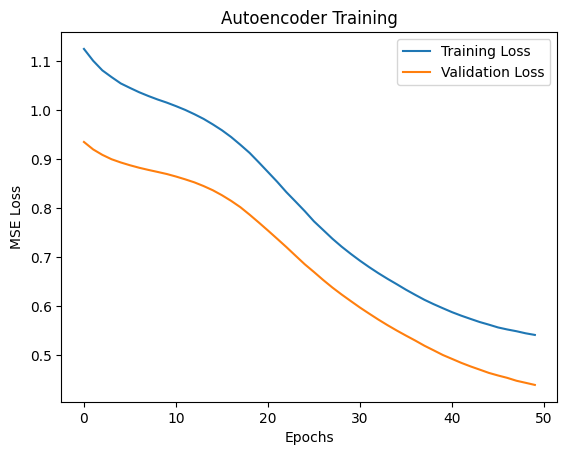

In [ ]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training")
plt.legend()
plt.show()

In [ ]:
encoder = Model(
    inputs=input_layer,
    outputs=latent
)

X_encoded = encoder.predict(X_test)

print("Original shape:", X_test.shape)
print("Encoded shape:", X_encoded.shape)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Original shape: (36, 13)
Encoded shape: (36, 3)


In [ ]:
X_reconstructed = autoencoder.predict(X_test)

print(X_reconstructed.shape)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
(36, 13)


In [ ]:
reconstruction_error = np.mean(
    np.square(X_test - X_reconstructed)
)

print("Reconstruction Error:", reconstruction_error)

Reconstruction Error: 0.43893235177073636
